# Manual matcher experiment

We compare `brandName`, `activeSubstances`, and `licenceHolder` across DPD, EMA, and FDA. The experiment evaluates three rules:

- **Exact:** Equal nonempty normalized brand names and substance text, with holder agreement. Substance order matters.
- **Salt:** Equal normalized brands and nonempty substance sets after removing common salt and hydration terms, with holder agreement. Substance order does not matter.
- **Fuzzy:** Equal cleaned substance sets, shared substance tokens, and brand-name `SequenceMatcher` similarity of at least `0.80`, with holder agreement.

**Holder agreement:** Normalize case, punctuation, and whitespace, then remove common company suffixes such as `LTD`, `INC`, `GMBH`, and `B.V.`. Compare word sets using the overlap coefficient: shared words divided by the size of the smaller set. Require at least `0.80` when both holders are present. Extra words in the longer name are tolerated. If either original holder is missing, skip the condition. Present names containing only removed suffixes fail the check. No company aliases are defined.

Evaluate each rule alone, each pair of rules, and all three together. A combination accepts a pair when any included rule accepts it. All seven configurations use the same test pairs.

In [41]:
import re
from pathlib import Path
from difflib import SequenceMatcher
from itertools import combinations
from typing import Any

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

project_root = Path.cwd()
if not (project_root / 'data').exists():
    project_root = project_root.parent

fuzzy_threshold = 0.80
holder_threshold = 0.80
input_path = project_root / 'data/5_golden_standard_pair/golden_standard_pair_complete/gs_pair_test.csv'

In [42]:
COMPANY_SUFFIXES = {
    'LTD', 'LIMITED', 'INC', 'INCORPORATED', 'CORP', 'CORPORATION',
    'CO', 'COMPANY', 'LLC', 'LLP', 'PLC', 'GMBH', 'AG',
    'BV', 'NV', 'SA', 'SAS', 'SRL', 'SPA',
}

COMMON_PHARMACEUTICAL_SALTS = {
    'HYDROCHLORIDE', 'HCL', 'DIHYDROCHLORIDE', 'MONOHYDROCHLORIDE',
    'SODIUM', 'DISODIUM', 'TRISODIUM', 'POTASSIUM', 'DIPOTASSIUM',
    'SULFATE', 'BISULFATE', 'SULPHATE',
    'BESYLATE', 'BESILATE', 'MESYLATE', 'MESILATE', 'TOSYLATE',
    'ACETATE', 'DIACETATE', 'MALEATE', 'FUMARATE', 'TARTRATE',
    'BITARTRATE', 'SUCCINATE', 'CALCIUM', 'MAGNESIUM', 'ZINC',
    'BROMIDE', 'CHLORIDE', 'IODIDE', 'PHOSPHATE', 'DIPHOSPHATE',
    'MONOPHOSPHATE', 'CITRATE', 'GLUCONATE', 'LACTATE', 'PROPIONATE',
    'MONOHYDRATE', 'DIHYDRATE', 'TRIHYDRATE', 'HEMIHYDRATE', 'ANHYDROUS',
    'AS', 'OF', 'WITH', 'BASE',
}


def strip_salts(value: Any) -> set[str]:
    """Extract substance names after removing common modifiers.

    Parameters
    ----------
    value : scalar
        Semicolon-separated substance text; missing values are allowed.

    Returns
    -------
    set[str]
        Cleaned names containing retained tokens longer than two characters.
    """
    if value is None or pd.isna(value) or not str(value).strip():
        return set()
    clean = re.sub(r'[\(\)\[\],]', ' ', str(value).upper())
    base_substances = set()
    for substance in clean.split(';'):
        words = [
            word for word in re.findall(r'\b[A-Z0-9]+\b', substance)
            if word not in COMMON_PHARMACEUTICAL_SALTS and len(word) > 2
        ]
        if words:
            base_substances.add(' '.join(words))
    return base_substances


def parse_substance_tokens(value: Any) -> set[str]:
    """Extract substance word tokens after removing common modifiers.

    Parameters
    ----------
    value : scalar
        Substance text; missing values are allowed.

    Returns
    -------
    set[str]
        Retained uppercase tokens longer than two characters.
    """
    if value is None or pd.isna(value) or not str(value).strip():
        return set()
    clean = re.sub(r'[\(\)\[\],;]', ' ', str(value).upper())
    return {
        word for word in re.findall(r'\b[A-Z0-9]+\b', clean)
        if word not in COMMON_PHARMACEUTICAL_SALTS and len(word) > 2
    }


def score_predictions(y_true, y_pred):
    """Calculate match-class metrics and macro F1.

    Parameters
    ----------
    y_true : array-like
        Reviewed binary labels.
    y_pred : array-like
        Predicted binary labels.

    Returns
    -------
    dict
        Precision, recall, match F1, and macro F1.
    """
    return {
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'match_f1': f1_score(y_true, y_pred, zero_division=0),
        'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
    }

## Data

Evaluate all configurations on `gs_pair_test.csv` (525 reviewed pairs). The brand and holder similarity thresholds are fixed at `0.80`. The threshold sweep varies brand similarity to describe test-set sensitivity.

In [43]:
pairs = pd.read_csv(input_path)
required = ['id1', 'id2', 'source_pair', 'hard', 'match', 'brandName1', 'brandName2', 'activeSubstances1', 'activeSubstances2', 'licenceHolder1', 'licenceHolder2']
assert set(required).issubset(pairs.columns)
assert pairs['match'].notna().all() and pairs['match'].isin([0, 1]).all()
assert not pairs.duplicated(['id1', 'id2']).any()

test_idx = pairs.index
print(f'Test: {len(pairs)} pairs from {input_path.name}')
display(pairs.groupby(['source_pair', 'match']).size().unstack(fill_value=0))
display(pairs[required[5:]].isna().sum().rename('missing').to_frame())
display(pairs[required].head(3))

Test: 525 pairs from gs_pair_test.csv


match,0,1
source_pair,,
dpd_ema,87,63
dpd_fda,79,37
ema_fda,173,86


,missing
brandName1,0
brandName2,0
activeSubstances1,0
activeSubstances2,0
licenceHolder1,10
licenceHolder2,14


,id1,id2,source_pair,hard,match,brandName1,brandName2,activeSubstances1,activeSubstances2,licenceHolder1,licenceHolder2
0,EMA_EMEA/H/C/001159,FDA_EXFORGE HCT|AMLODIPINE BESYLATE; HYDROCHLO...,ema_fda,1,1,Copalia HCT,EXFORGE HCT,amlodipine; valsartan; hydrochlorothiazide,AMLODIPINE BESYLATE; HYDROCHLOROTHIAZIDE; VALS...,Novartis Europharm Limited,NOVARTIS
1,DPD_LEVOFLOXACIN|LEVOFLOXACIN,FDA_LEVOFLOXACIN|LEVOFLOXACIN; SODIUM CHLORIDE,dpd_fda,1,0,LEVOFLOXACIN,LEVOFLOXACIN,LEVOFLOXACIN,LEVOFLOXACIN; SODIUM CHLORIDE,COBALT PHARMACEUTICALS COMPANY,SICOR PHARMS
2,EMA_EMEA/H/C/002753,FDA_TIVICAY PD|DOLUTEGRAVIR SODIUM,ema_fda,1,1,Tivicay,TIVICAY PD,dolutegravir,DOLUTEGRAVIR SODIUM,ViiV Healthcare BV,VIIV HLTHCARE


## Matching rules

Each rule includes `holder_agreement`: require holder token overlap after company-suffix removal of at least `0.80` when both names are available, and bypass the condition when either is missing. Then apply Exact, Salt, or Fuzzy brand/substance matching.

Rules run independently. Combinations accept a pair when any included rule accepts it. Overlapping rules can produce identical predictions.

In [44]:
# Normalize Text
text_columns = ['brandName1', 'brandName2', 'activeSubstances1', 'activeSubstances2', 'licenceHolder1', 'licenceHolder2']
normalized = pairs[text_columns].fillna('').astype(str)
for column in text_columns:
    normalized[column] = (
        normalized[column].str.upper()
        .str.replace(r'[^\w\s]', ' ', regex=True)
        .str.split().str.join(' ')
    )

# Prepare Attributes
brand1 = normalized['brandName1']
brand2 = normalized['brandName2']
substance1 = normalized['activeSubstances1']
substance2 = normalized['activeSubstances2']
base1 = pairs['activeSubstances1'].map(strip_salts)
base2 = pairs['activeSubstances2'].map(strip_salts)
tokens1 = pairs['activeSubstances1'].map(parse_substance_tokens)
tokens2 = pairs['activeSubstances2'].map(parse_substance_tokens)

# Check Licence Holders
holder1 = normalized['licenceHolder1']
holder2 = normalized['licenceHolder2']
holder_missing = holder1.eq('') | holder2.eq('')
# Normalize dotted legal suffixes, then remove common company suffixes
holder_token_sets = []
for holder_names in [holder1, holder2]:
    token_sets = []
    for name in holder_names:
        name = re.sub(r'\b(?:B V|N V|S A|S R L|S P A|L L C|L L P)\b',
                      lambda match: match.group().replace(' ', ''), name)
        token_sets.append(set(name.split()) - COMPANY_SUFFIXES)
    holder_token_sets.append(token_sets)
holder_tokens1, holder_tokens2 = holder_token_sets

# Overlap coefficient tolerates extra words in the longer company name
holder_similarity = pd.Series(
    [len(a & b) / min(len(a), len(b)) if a and b else 0.0
     for a, b in zip(holder_tokens1, holder_tokens2)],
    index=pairs.index,
)
# Skip only when the original holder is empty; suffix-only names do not agree
holder_agreement = holder_missing | holder_similarity.ge(holder_threshold)

# Rule 1: Exact brand and substance text, with holder agreement
exact = (brand1 == brand2) & brand1.ne('') & (substance1 == substance2) & substance1.ne('') & holder_agreement

# Shared substance comparisons
same_base = pd.Series([a == b and bool(a) for a, b in zip(base1, base2)], index=pairs.index)
shared_tokens = pd.Series([bool(a & b) for a, b in zip(tokens1, tokens2)], index=pairs.index)

# Rule 2: Exact brand and salt-normalized substance sets, with holder agreement
salt = (brand1 == brand2) & brand1.ne('') & same_base & holder_agreement

# Rule 3: Fuzzy brand and salt-normalized substance sets, with holder agreement
brand_similarity = pd.Series(
    [SequenceMatcher(None, a, b).ratio() for a, b in zip(brand1, brand2)],
    index=pairs.index,
)
fuzzy_eligible = shared_tokens & same_base & holder_agreement
fuzzy = fuzzy_eligible & brand_similarity.ge(fuzzy_threshold)

# Evaluate singles, pairs, and all rules
rule_predictions = pd.DataFrame({'Exact': exact, 'Salt': salt, 'Fuzzy': fuzzy})
predictions = pd.DataFrame(index=pairs.index)
for count in [1, 2, 3]:
    for included_rules in combinations(rule_predictions.columns, count):
        name = ' + '.join(included_rules)
        predictions[name] = rule_predictions[list(included_rules)].any(axis=1).astype(int)

all_rules_name = 'Exact + Salt + Fuzzy'

# Attribute accepted pairs in pipeline order for error review
rule = pd.Series('unmatched', index=pairs.index)
rule.loc[fuzzy] = 'fuzzy'
rule.loc[salt] = 'salt'
rule.loc[exact] = 'exact'
assert predictions.shape[1] == 7
assert predictions[all_rules_name].equals((exact | salt | fuzzy).astype(int))

## Results

Compare the three individual rules, three pairs, and all rules on the same test pairs. Precision, recall, and F1 refer to matches; macro F1 averages both classes. The threshold table uses test pairs only.

In [45]:
# Compare thresholds on test pairs
threshold_results = []
for threshold in [0.70, 0.75, 0.80, 0.85, 0.90, 0.95]:
    predicted = (exact | salt | (fuzzy_eligible & brand_similarity.ge(threshold))).astype(int)
    threshold_results.append({
        'threshold': threshold,
        **score_predictions(pairs.loc[test_idx, 'match'], predicted.loc[test_idx]),
    })
display(pd.DataFrame(threshold_results).round(4))

,threshold,precision,recall,match_f1,macro_f1
0,0.70,0.9649,0.2957,0.4527,0.6439
1,0.75,0.9818,0.2903,0.4481,0.6419
2,0.80,0.9815,0.2849,0.4417,0.6381
3,0.85,0.9804,0.2688,0.4219,0.6267
4,0.90,1.0000,0.2527,0.4034,0.6166
5,0.95,1.0000,0.2527,0.4034,0.6166


## Threshold comparison

Scores for the combined matcher across brand-similarity thresholds on all 525 test pairs. Holder token overlap after company-suffix removal stays fixed at `0.80`, with missing holders bypassing the condition. The main experiment uses brand threshold `0.80`.

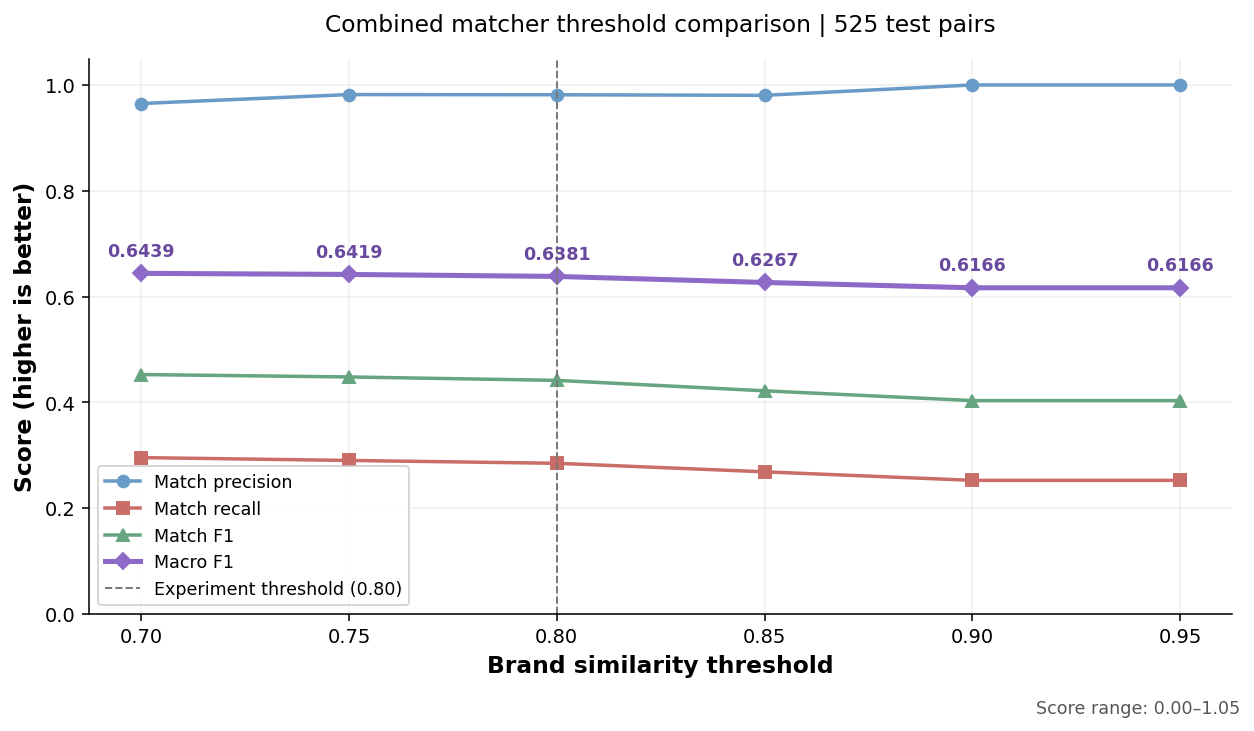

In [46]:
# Plot threshold sensitivity
threshold_scores = pd.DataFrame(threshold_results)
fig, ax = plt.subplots(figsize=(9, 5.2), dpi=140)
metric_styles = [
    ('precision', 'Match precision', '#699bc8', 'o'),
    ('recall', 'Match recall', '#c96d68', 's'),
    ('match_f1', 'Match F1', '#66a580', '^'),
    ('macro_f1', 'Macro F1', '#8d6ac8', 'D'),
]
for metric, label, color, marker in metric_styles:
    ax.plot(
        threshold_scores['threshold'], threshold_scores[metric],
        label=label, color=color, marker=marker,
        linewidth=2.6 if metric == 'macro_f1' else 1.8, markersize=6,
    )

# Label macro F1 and the experiment threshold
for row in threshold_scores.itertuples():
    ax.annotate(
        f'{row.macro_f1:.4f}', (row.threshold, row.macro_f1),
        xytext=(0, 9), textcoords='offset points',
        ha='center', fontsize=9, fontweight='bold', color='#68499e',
    )
ax.axvline(fuzzy_threshold, color='#777777', linestyle='--', linewidth=1, label=f'Experiment threshold ({fuzzy_threshold:.2f})')
ax.set_xticks(threshold_scores['threshold'])
ax.set_xlabel('Brand similarity threshold', fontsize=12, fontweight='bold')
ax.set_ylabel('Score (higher is better)', fontsize=12, fontweight='bold')
ax.set_title(f'Combined matcher threshold comparison | {len(test_idx):,} test pairs', pad=14)
# Set the score range manually
ax.set_ylim(0.00, 1.05)
ax.grid(alpha=0.18)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='best', frameon=True, fontsize=9)
fig.text(0.99, 0.01, 'Score range: 0.00–1.05', ha='right', fontsize=9, color='#555555')
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## Test metrics

Compare all seven configurations on the same test pairs.

In [47]:
# Compare rule contributions on test pairs
test_results = pd.DataFrame([
    {'matcher': name, **score_predictions(pairs.loc[test_idx, 'match'], predictions.loc[test_idx, name])}
    for name in predictions
]).set_index('matcher')
display(test_results.round(4))

,precision,recall,match_f1,macro_f1
matcher,,,,
Exact,1.0000,0.2151,0.3540,0.5884
Salt,1.0000,0.2527,0.4034,0.6166
Fuzzy,0.9815,0.2849,0.4417,0.6381
Exact + Salt,1.0000,0.2527,0.4034,0.6166
Exact + Fuzzy,0.9815,0.2849,0.4417,0.6381
Salt + Fuzzy,0.9815,0.2849,0.4417,0.6381
Exact + Salt + Fuzzy,0.9815,0.2849,0.4417,0.6381


## Rule contributions

Count accepted matches and nonmatches using the first applicable rule: Exact, Salt, then Fuzzy.

In [48]:
display(pd.crosstab(rule.loc[test_idx], pairs.loc[test_idx, 'match']).rename(columns={0: 'nonmatch', 1: 'match'}))

match,nonmatch,match
row_0,,
exact,0,40
fuzzy,1,6
salt,0,7
unmatched,338,133


## Review

Compare every configuration by source pair and difficulty on test pairs. Error examples below use the combined matcher. Salt removal and brand similarity can merge distinct products; different regional brand names can remain unmatched.

In [49]:
test = pairs.loc[test_idx].copy()
test['prediction'] = predictions.loc[test_idx, all_rules_name]
test['rule'] = rule.loc[test_idx]
# Score each configuration within each group
breakdown = []
for column in ['source_pair', 'hard']:
    for value, group in test.groupby(column):
        for matcher in predictions.columns:
            breakdown.append({
                'group': column, 'value': value, 'matcher': matcher, 'pairs': len(group),
                **score_predictions(group['match'], predictions.loc[group.index, matcher]),
            })
breakdown_results = pd.DataFrame(breakdown)

In [50]:
# Source-pair metrics
source_pair_results = breakdown_results[breakdown_results['group'] == 'source_pair'].drop(columns='group')
display(source_pair_results.round(4))

,value,matcher,pairs,precision,recall,match_f1,macro_f1
0,dpd_ema,Exact,150,1.0000,0.2063,0.3421,0.5594
1,dpd_ema,Salt,150,1.0000,0.2540,0.4051,0.5962
2,dpd_ema,Fuzzy,150,1.0000,0.2857,0.4444,0.6195
3,dpd_ema,Exact + Salt,150,1.0000,0.2540,0.4051,0.5962
4,dpd_ema,Exact + Fuzzy,150,1.0000,0.2857,0.4444,0.6195
5,dpd_ema,Salt + Fuzzy,150,1.0000,0.2857,0.4444,0.6195
6,dpd_ema,Exact + Salt + Fuzzy,150,1.0000,0.2857,0.4444,0.6195
7,dpd_fda,Exact,116,1.0000,0.1892,0.3182,0.5793
8,dpd_fda,Salt,116,1.0000,0.2703,0.4255,0.6398
9,dpd_fda,Fuzzy,116,0.9167,0.2973,0.4490,0.6507


In [51]:
# Difficulty metrics
hard_results = breakdown_results[breakdown_results['group'] == 'hard'].drop(columns='group')
display(hard_results.round(4))

,value,matcher,pairs,precision,recall,match_f1,macro_f1
21,0,Exact,290,1.0000,0.4444,0.6154,0.7521
22,0,Salt,290,1.0000,0.4444,0.6154,0.7521
23,0,Fuzzy,290,1.0000,0.4444,0.6154,0.7521
24,0,Exact + Salt,290,1.0000,0.4444,0.6154,0.7521
25,0,Exact + Fuzzy,290,1.0000,0.4444,0.6154,0.7521
26,0,Salt + Fuzzy,290,1.0000,0.4444,0.6154,0.7521
27,0,Exact + Salt + Fuzzy,290,1.0000,0.4444,0.6154,0.7521
28,1,Exact,235,0.0000,0.0000,0.0000,0.3717
29,1,Salt,235,1.0000,0.0729,0.1359,0.4467
30,1,Fuzzy,235,0.9286,0.1354,0.2364,0.5015


## Source pairs and difficulty

Cells show test macro F1 for each configuration. Both charts use the same 0–1 color scale; n is the number of pairs in each group. Difficulty follows the saved hard label (0 = ordinary, 1 = difficult).

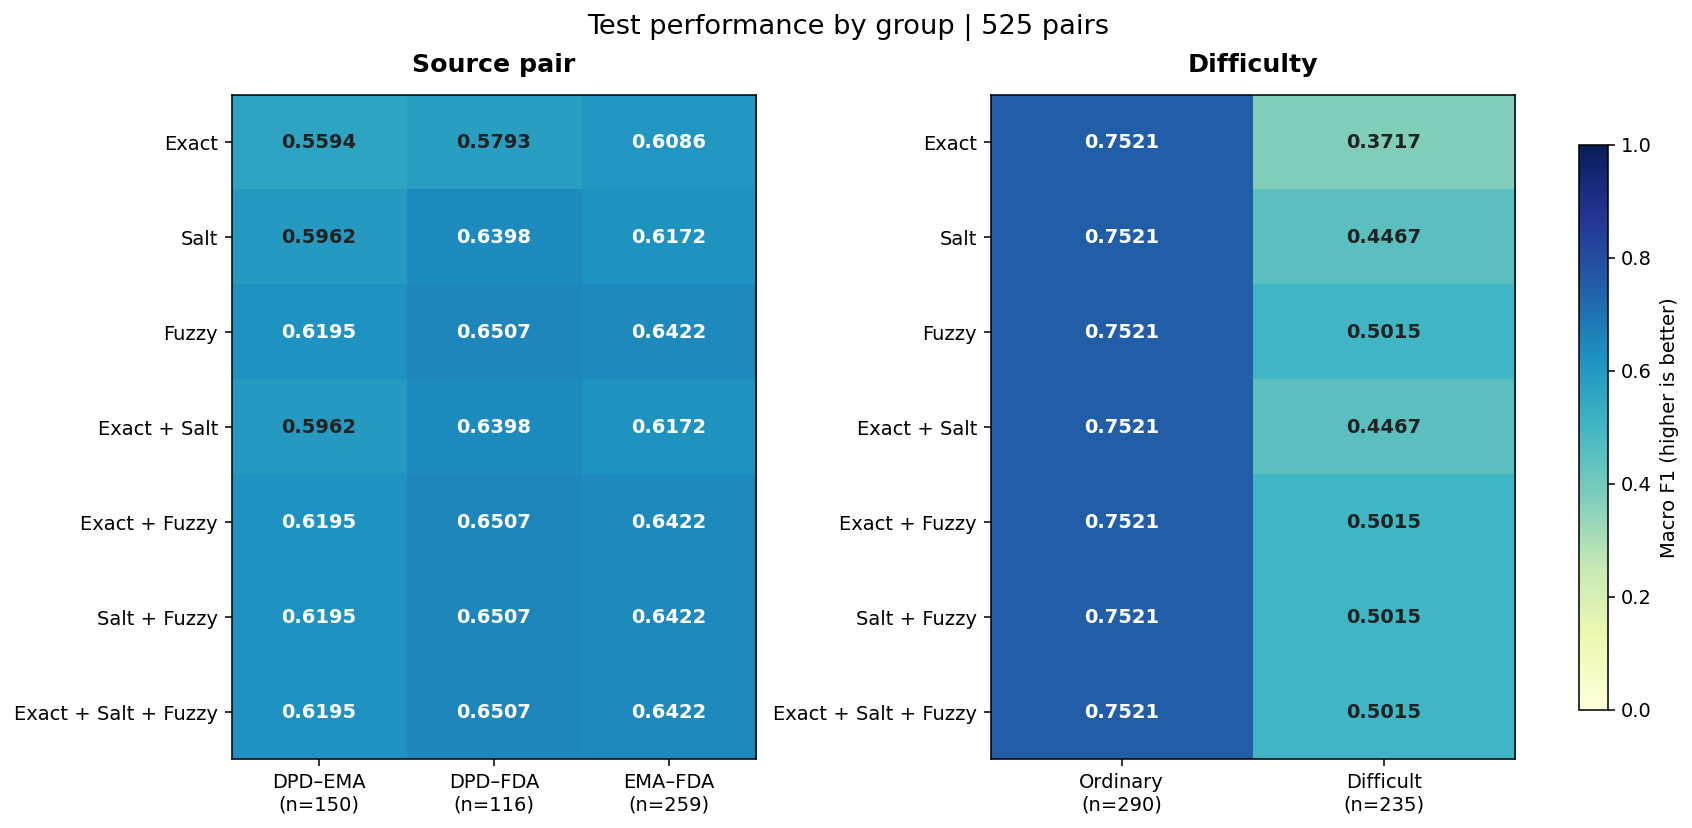

In [52]:
# Plot macro F1 by source pair and difficulty
fig, axes = plt.subplots(1, 2, figsize=(12, 5.8), dpi=140, layout='constrained')
for ax, column, title in zip(axes, ['source_pair', 'hard'], ['Source pair', 'Difficulty']):
    group_results = breakdown_results[breakdown_results['group'] == column]
    scores_by_group = group_results.pivot(index='matcher', columns='value', values='macro_f1')
    scores_by_group = scores_by_group.reindex(predictions.columns)
    image = ax.imshow(scores_by_group, cmap='YlGnBu', vmin=0, vmax=1, aspect='auto')
    group_counts = test.groupby(column).size()
    labels = []
    for value in scores_by_group.columns:
        group_label = str(value).upper().replace('_', '–') if column == 'source_pair' else {0: 'Ordinary', 1: 'Difficult'}[value]
        labels.append(f'{group_label}\n(n={group_counts[value]})')
    ax.set_xticks(range(len(labels)), labels, fontsize=10)
    ax.set_yticks(range(len(scores_by_group)), scores_by_group.index, fontsize=10)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=12)
    for row in range(len(scores_by_group)):
        for col in range(len(scores_by_group.columns)):
            score = scores_by_group.iloc[row, col]
            ax.text(col, row, f'{score:.4f}', ha='center', va='center',
                    color='white' if score > 0.6 else '#222222', fontsize=10, fontweight='bold')
fig.colorbar(image, ax=axes, label='Macro F1 (higher is better)', shrink=0.85)
fig.suptitle(f'Test performance by group | {len(test)} pairs', fontsize=14)
plt.show()

## Confusion matrices

Each matrix uses the same 525 test pairs. Rows are actual labels and columns are predicted labels. Cells show counts (TN, FP, FN, TP), with a shared color scale across all configurations.

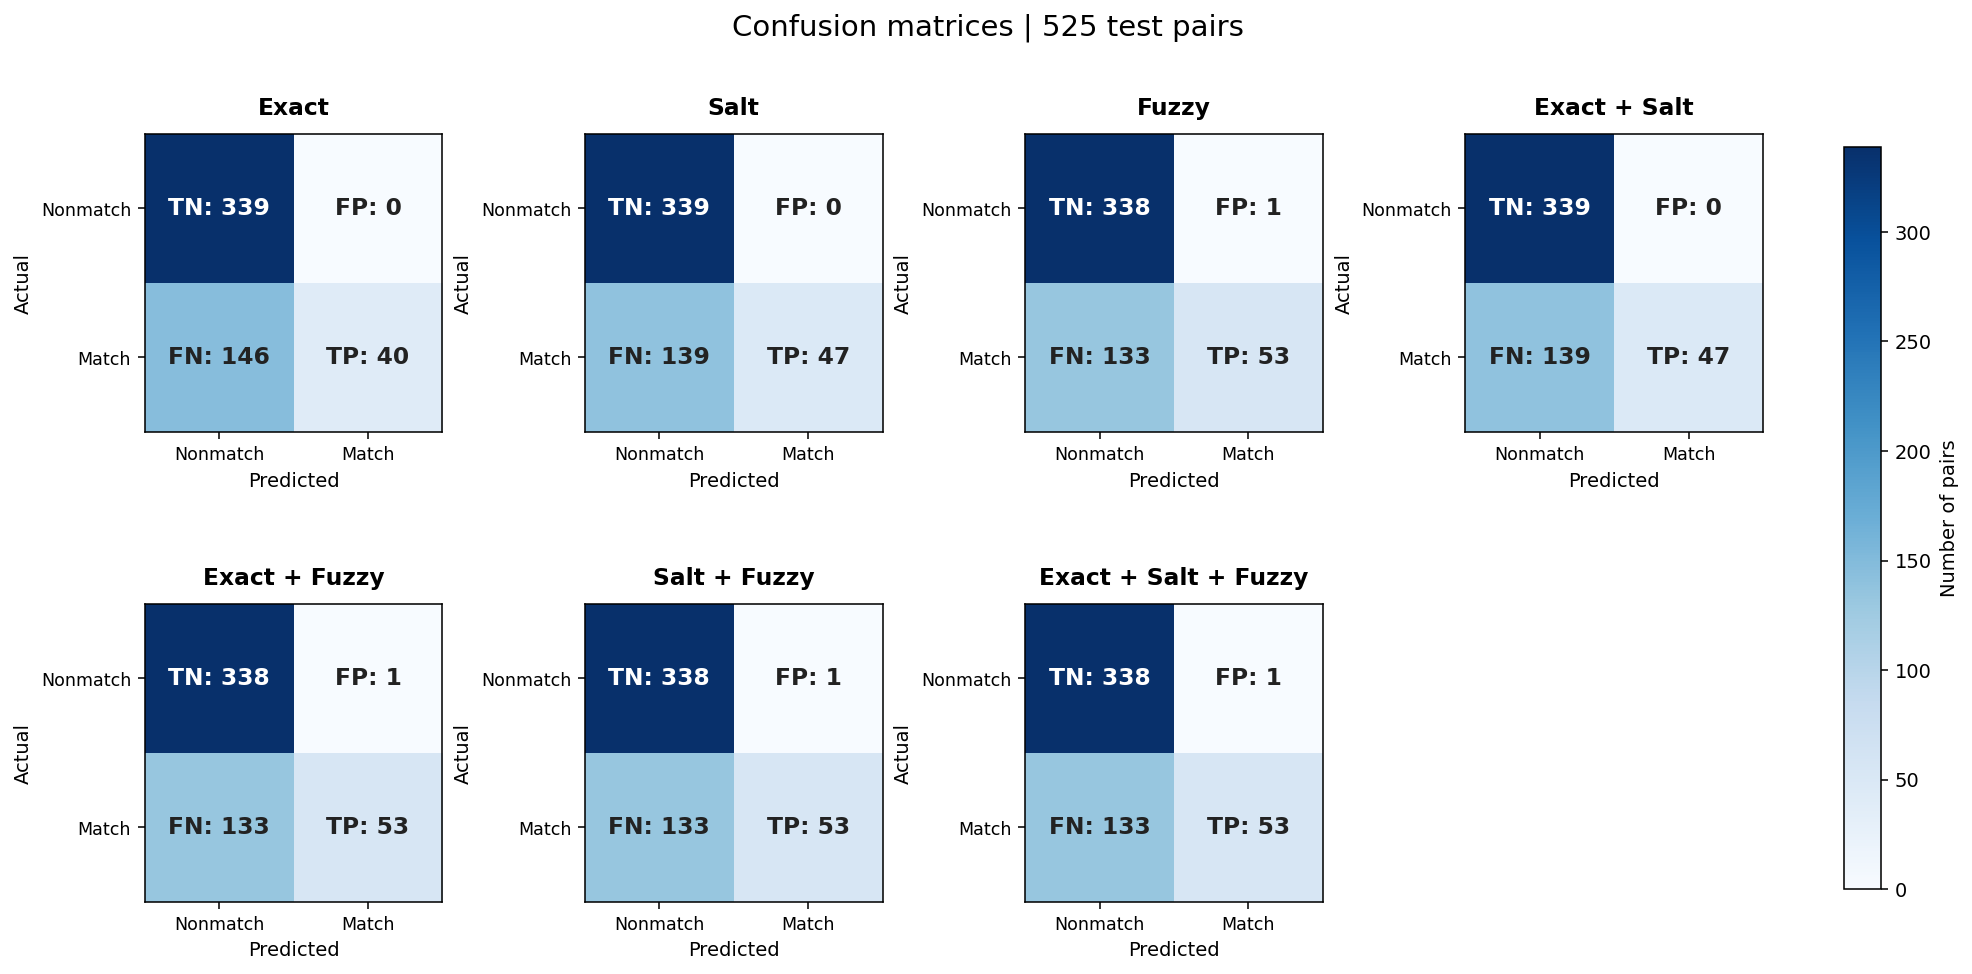

In [53]:
# Calculate all confusion matrices
confusion_matrices = {
    matcher: confusion_matrix(test['match'], predictions.loc[test_idx, matcher], labels=[0, 1])
    for matcher in predictions.columns
}
assert all(matrix.sum() == len(test) for matrix in confusion_matrices.values())
max_count = max(matrix.max() for matrix in confusion_matrices.values())

# Plot on a shared count scale
fig, axes = plt.subplots(2, 4, figsize=(14, 7), dpi=140, layout='constrained')
cell_names = [['TN', 'FP'], ['FN', 'TP']]
for ax, (matcher, matrix) in zip(axes.flat, confusion_matrices.items()):
    image = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=max_count)
    ax.set_title(matcher, fontsize=12, fontweight='bold', pad=10)
    ax.set_xticks([0, 1], ['Nonmatch', 'Match'], fontsize=9)
    ax.set_yticks([0, 1], ['Nonmatch', 'Match'], fontsize=9)
    ax.set_xlabel('Predicted', fontsize=10)
    ax.set_ylabel('Actual', fontsize=10)
    for row in range(2):
        for col in range(2):
            count = matrix[row, col]
            ax.text(col, row, f'{cell_names[row][col]}: {count}',
                    ha='center', va='center', fontsize=12, fontweight='bold',
                    color='white' if count > max_count / 2 else '#222222')
axes.flat[-1].set_visible(False)
fig.colorbar(image, ax=list(axes.flat[:-1]), label='Number of pairs', shrink=0.8)
fig.suptitle(f'Confusion matrices | {len(test)} test pairs', fontsize=15)
plt.show()

## False positives

Examples accepted by the combined matcher with a reviewed nonmatch label.

In [54]:
review_columns = ['source_pair', 'brandName1', 'brandName2', 'activeSubstances1', 'activeSubstances2', 'licenceHolder1', 'licenceHolder2', 'match', 'prediction', 'rule']
false_positives = test[(test['match'] == 0) & (test['prediction'] == 1)]
print(f'False positives: {len(false_positives)}')
display(false_positives[review_columns].head(8))

False positives: 1


,source_pair,brandName1,brandName2,activeSubstances1,activeSubstances2,licenceHolder1,licenceHolder2,match,prediction,rule
220,dpd_fda,ALPHAGAN,ALPHAGAN P,BRIMONIDINE,BRIMONIDINE TARTRATE,ABBVIE CORPORATION,ABBVIE,0,1,fuzzy


## False negatives

Examples rejected by the combined matcher with a reviewed match label.

In [55]:
false_negatives = test[(test['match'] == 1) & (test['prediction'] == 0)]
print(f'False negatives: {len(false_negatives)}')
display(false_negatives[review_columns].head(8))

False negatives: 133


,source_pair,brandName1,brandName2,activeSubstances1,activeSubstances2,licenceHolder1,licenceHolder2,match,prediction,rule
0,ema_fda,Copalia HCT,EXFORGE HCT,amlodipine; valsartan; hydrochlorothiazide,AMLODIPINE BESYLATE; HYDROCHLOROTHIAZIDE; VALS...,Novartis Europharm Limited,NOVARTIS,1,0,unmatched
2,ema_fda,Tivicay,TIVICAY PD,dolutegravir,DOLUTEGRAVIR SODIUM,ViiV Healthcare BV,VIIV HLTHCARE,1,0,unmatched
7,ema_fda,Hetlioz,HETLIOZ,tasimelteon,TASIMELTEON,Vanda Pharmaceuticals Netherlands B.V.,VANDA PHARMS INC,1,0,unmatched
9,ema_fda,CellCept,CELLCEPT,mycophenolate mofetil,MYCOPHENOLATE MOFETIL HYDROCHLORIDE,Roche Registration GmbH,ROCHE PALO,1,0,unmatched
16,dpd_fda,MYFEMBREE,MYFEMBREE,ESTRADIOL; NORETHINDRONE; RELUGOLIX,ESTRADIOL; NORETHINDRONE ACETATE; RELUGOLIX,KNIGHT THERAPEUTICS INC.,SUMITOMO PHARMA AM,1,0,unmatched
22,ema_fda,Stelara,STELARA,ustekinumab,USTEKINUMAB,Janssen-Cilag International NV,CENTOCOR ORTHO BIOTECH INC,1,0,unmatched
26,dpd_ema,TEVA-TELMISARTAN,Telmisartan Teva,TELMISARTAN,telmisartan,TEVA CANADA LIMITED,Teva B.V.,1,0,unmatched
32,ema_fda,Noxafil,NOXAFIL,posaconazole,POSACONAZOLE,Merck Sharp and Dohme B.V,SCHERING,1,0,unmatched


## Macro F1 comparison

Test macro F1 for all seven configurations at fuzzy threshold 0.80. Higher is better. The x-axis is zoomed to show the differences; labels show absolute scores.

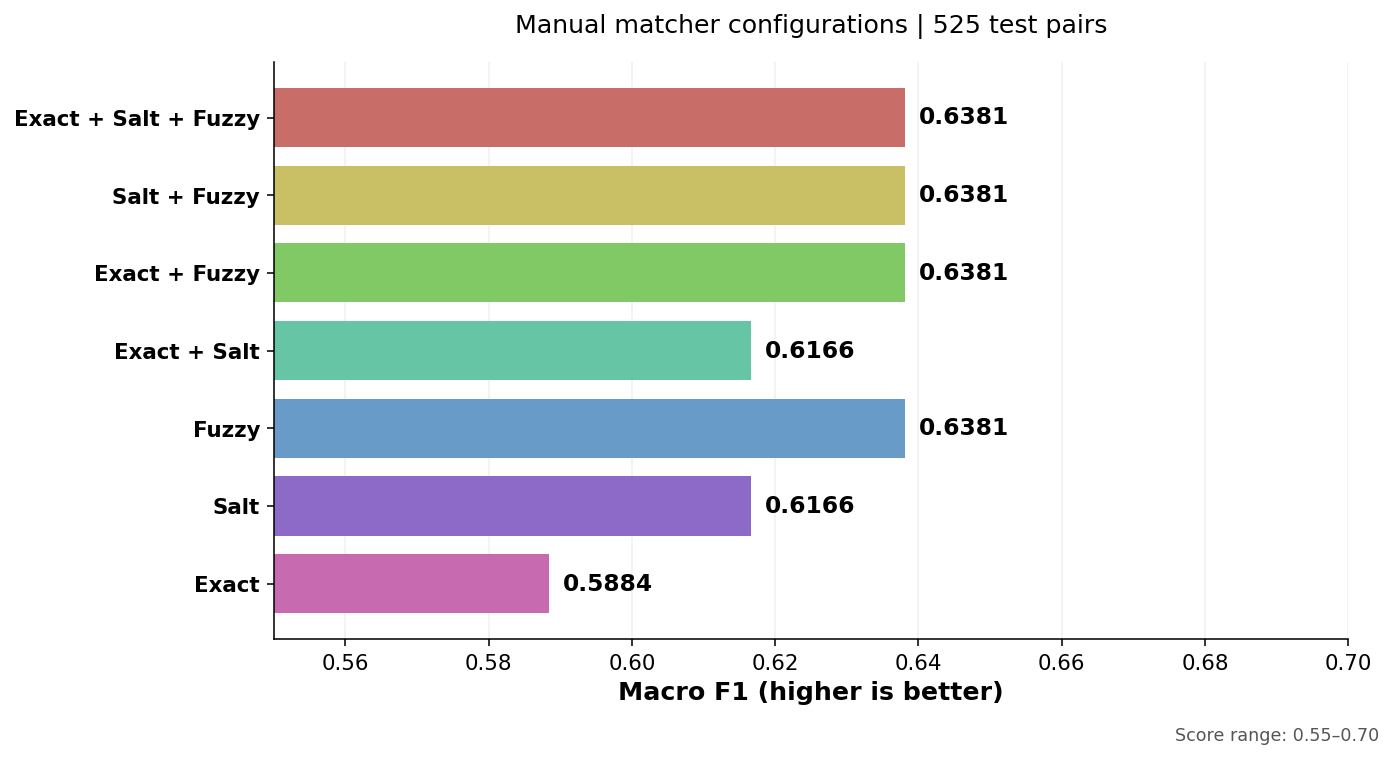

In [56]:
# Plot test results
chart_results = test_results.iloc[::-1]
scores = chart_results['macro_f1']
colors = ['#c96d68', '#c9bf65', '#80c965', '#66c5a5', '#699bc8', '#8d6ac8', '#c76ab0']
fig, ax = plt.subplots(figsize=(10, 5.4), dpi=140)
bars = ax.barh(chart_results.index, scores, color=colors, height=0.76)
ax.invert_yaxis()

# Set the score range manually
ax.set_xlim(0.55, 0.70)
ax.bar_label(bars, labels=[f'{score:.4f}' for score in scores], padding=7, fontsize=12, fontweight='bold')
ax.set_xlabel('Macro F1 (higher is better)', fontsize=13, fontweight='bold')
ax.set_title(f'Manual matcher configurations | {len(test_idx)} test pairs', fontsize=13, pad=15)
ax.tick_params(axis='both', labelsize=11)
for label in ax.get_yticklabels():
    label.set_fontweight('bold')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, position: f'{value:.2f}'))
ax.grid(axis='x', alpha=0.18)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
fig.text(0.99, 0.01, 'Score range: 0.55–0.70', ha='right', fontsize=9, color='#555555')
fig.tight_layout(rect=(0, 0.03, 1, 1))

plt.show()

## Conclusion

The rules show high precision and low recall: accepted pairs are usually correct, while many true matches remain unmatched. Fuzzy and the combinations containing it achieve the highest macro F1 by recovering additional matches with a small loss in precision.

A possible explanation is that each rule requires agreement across brand, the full substance set, and the available licence holders. These conditions make acceptance selective. Regional brand names, substance spelling differences, and company abbreviations can cause a true match to fail one condition. Different licence-holder names may share too few exact words even after company-suffix removal.

Salt normalization and token overlap handle some naming variation, but the remaining conditions still exclude many true matches. Missing holders bypass the holder check; pairs with two present holders must pass it. Lowering only the brand threshold has limited effect because it cannot recover pairs rejected by the substance or holder conditions.